In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error, mean_absolute_error

CORRELATION_METHOD = "pearson"
# =============================================================================
# Paths
# =============================================================================

BASE_DIR = Path(
    "/Users/f007qrc/Library/CloudStorage/GoogleDrive-anna.m.langener@dartmouth.edu/"
    ".shortcut-targets-by-id/1_T-CzrkNtF9QAhex6qrEOA0ZQIL7g5u5/"
    "SensingIndividualized"
)

RESULTS_ROOT = BASE_DIR / "results_true_pred"
DATA_DIR = BASE_DIR / "deeplearning_data" / "pred"

OUTER_CFG = {
    "train_size": 135,
    "test_size": 3,
    "step_size": 3,
}

SUMMARY_SAVE_PATH = RESULTS_ROOT / "results_summary_table.csv"

ALPHA = 0.05


# =============================================================================
# Helper functions
# =============================================================================

def safe_torch_load(path):
    """
    Load a PyTorch file while remaining compatible with newer and older
    PyTorch versions.
    """
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def pooled_correlation(
    y_true,
    y_pred,
    method=CORRELATION_METHOD,
    alpha=ALPHA,
):
    """
    Compute a pooled correlation across all test observations.

    Parameters
    ----------
    y_true : array-like
        Observed values.
    y_pred : array-like
        Predicted values.
    method : {"spearman", "pearson"}
        Correlation method.
    alpha : float
        Significance threshold.

    Returns
    -------
    correlation : float
        Pearson's r or Spearman's rho.
    p_value : float
        Two-sided p-value.
    significant : bool
        Whether p_value < alpha.
    """
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    if len(y_true) < 3:
        return np.nan, np.nan, False

    if np.ptp(y_true) == 0 or np.ptp(y_pred) == 0:
        return np.nan, np.nan, False

    method = method.lower()

    if method == "spearman":
        correlation, p_value = spearmanr(y_true, y_pred)
    elif method == "pearson":
        correlation, p_value = pearsonr(y_true, y_pred)
    else:
        raise ValueError(
            "method must be either 'spearman' or 'pearson'. "
            f"Received: {method!r}"
        )

    if not np.isfinite(correlation) or not np.isfinite(p_value):
        return np.nan, np.nan, False

    significant = bool(p_value < alpha)

    return float(correlation), float(p_value), significant


def get_expected_n_splits(
    participant_id,
    data_dir=DATA_DIR,
    outer_cfg=OUTER_CFG,
):
    """
    Compute the expected number of outer splits from the participant .npz file.

    This mirrors the preprocessing step in which the first questionnaire
    observation is removed.
    """
    file_path = data_dir / f"participant_{participant_id}_4h.npz"

    if not file_path.exists():
        return np.nan

    loaded = np.load(file_path, allow_pickle=True)

    n_samples = len(loaded["labels"])

    # The pipeline removes the first questionnaire observation
    n_samples -= 1

    train_size = outer_cfg["train_size"]
    test_size = outer_cfg["test_size"]
    step_size = outer_cfg["step_size"]

    n_splits = 0
    start = 0

    while start + train_size + test_size <= n_samples:
        n_splits += 1
        start += step_size

    return n_splits


def parse_result_filename(path):
    """
    Expected filenames:
        results_00092_negative.pth
        results_00011_cognitive.pth
        results_00011_positive.pth
    """
    match = re.match(
        r"results_(\d+)_(negative|cognitive|positive)\.pth$",
        path.name,
    )

    if match is None:
        return None, None

    participant_id = match.group(1)
    outcome = match.group(2)

    return participant_id, outcome


def make_error_row(
    path,
    participant_id,
    outcome,
    variant_folder,
    error_message,
):
    """
    Create a consistent summary row for files that could not be processed.
    """
    return {
        "variant_folder": variant_folder,
        "participant_id": participant_id,
        "outcome": outcome,
        "n_splits": np.nan,
        "expected_splits": get_expected_n_splits(participant_id),
        "complete": False,
        "n_test_obs": np.nan,
        "pooled_corr": np.nan,
        "pooled_corr_p": np.nan,
        "corr_significant": False,
        "corr_significance": "NA",
        "pooled_mse": np.nan,
        "pooled_mae": np.nan,
        "mean_split_mse": np.nan,
        "max_outer_i": np.nan,
        "missing_outer_ids": [],
        "file_path": str(path),
        "load_error": str(error_message),
    }


def summarize_result_file(path):
    """
    Load one result file and compute pooled performance metrics.
    """
    participant_id, outcome = parse_result_filename(path)

    if participant_id is None:
        return None

    variant_folder = path.parent.name

    try:
        results = safe_torch_load(path)
    except Exception as error:
        return make_error_row(
            path=path,
            participant_id=participant_id,
            outcome=outcome,
            variant_folder=variant_folder,
            error_message=error,
        )

    if not isinstance(results, list):
        return make_error_row(
            path=path,
            participant_id=participant_id,
            outcome=outcome,
            variant_folder=variant_folder,
            error_message=f"Expected list, got {type(results)}",
        )

    n_splits = len(results)
    expected_splits = get_expected_n_splits(participant_id)

    y_true_all = []
    y_pred_all = []
    split_mses = []
    outer_ids = []

    for item in results:
        if item is None:
            continue

        y_test = np.asarray(item.get("y_test", [])).reshape(-1)
        y_pred = np.asarray(item.get("y_pred", [])).reshape(-1)

        if len(y_test) == 0 or len(y_pred) == 0:
            continue

        if len(y_test) != len(y_pred):
            continue

        valid_mask = np.isfinite(y_test) & np.isfinite(y_pred)

        y_test = y_test[valid_mask]
        y_pred = y_pred[valid_mask]

        if len(y_test) == 0:
            continue

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)

        split_mses.append(mean_squared_error(y_test, y_pred))

        if "outer_i" in item:
            outer_ids.append(int(item["outer_i"]))

    if len(y_true_all) > 0:
        y_true_all = np.concatenate(y_true_all)
        y_pred_all = np.concatenate(y_pred_all)

        corr, corr_p_value, corr_significant = pooled_correlation(
            y_true_all,
            y_pred_all,
            method=CORRELATION_METHOD,
            alpha=ALPHA,
        )

        pooled_mse = mean_squared_error(y_true_all, y_pred_all)
        pooled_mae = mean_absolute_error(y_true_all, y_pred_all)
        n_test_obs = len(y_true_all)
    else:
        corr = np.nan
        corr_p_value = np.nan
        corr_significant = False
        pooled_mse = np.nan
        pooled_mae = np.nan
        n_test_obs = 0

    if np.isnan(corr_p_value):
        corr_significance = "NA"
    elif corr_p_value < 0.001:
        corr_significance = "***"
    elif corr_p_value < 0.01:
        corr_significance = "**"
    elif corr_p_value < 0.05:
        corr_significance = "*"
    else:
        corr_significance = "ns"

    if len(split_mses) > 0:
        mean_split_mse = float(np.mean(split_mses))
    else:
        mean_split_mse = np.nan

    if len(outer_ids) > 0:
        outer_ids = sorted(set(outer_ids))
        max_outer_i = max(outer_ids)

        missing_outer_ids = sorted(
            set(range(max_outer_i + 1)) - set(outer_ids)
        )
    else:
        missing_outer_ids = []
        max_outer_i = np.nan

    if np.isnan(expected_splits):
        complete = False
    else:
        complete = n_splits == expected_splits

    return {
        "variant_folder": variant_folder,
        "participant_id": participant_id,
        "outcome": outcome,
        "n_splits": n_splits,
        "expected_splits": expected_splits,
        "complete": complete,
        "n_test_obs": n_test_obs,
        "pooled_corr": corr,
        "pooled_corr_p": corr_p_value,
        "corr_significant": corr_significant,
        "corr_significance": corr_significance,
        "pooled_mse": pooled_mse,
        "pooled_mae": pooled_mae,
        "mean_split_mse": mean_split_mse,
        "max_outer_i": max_outer_i,
        "missing_outer_ids": missing_outer_ids,
        "file_path": str(path),
        "load_error": None,
    }


def add_variant_columns(summary_df):
    """
    Add model-type, retraining, and ensemble columns based on folder names.
    """
    df = summary_df.copy()

    if "variant_folder" not in df.columns:
        if "file_path" in df.columns:
            df["variant_folder"] = df["file_path"].apply(
                lambda x: Path(x).parent.name
            )
        else:
            raise ValueError(
                "summary_df needs either a 'variant_folder' column "
                "or a 'file_path' column."
            )

    def get_model_type(variant_name):
        variant_name = str(variant_name)

        if variant_name.startswith("combined_only"):
            return "combined_only"

        if variant_name.startswith("main"):
            return "main"

        if "future_chronos2" in variant_name:
            return "future_chronos2"

        if "chronos2_reg" in variant_name:
            return "chronos2_reg"

        return "unknown"

    def get_retrain_status(variant_name):
        variant_name = str(variant_name)

        if "no_retrain" in variant_name:
            return "no_retrain"

        if "retrain" in variant_name:
            return "retrain"

        return "unknown"

    def get_ensemble_status(variant_name):
        variant_name = str(variant_name)

        if "ensemble" in variant_name:
            return "ensemble"

        if "single" in variant_name:
            return "single"

        return "unknown"

    df["model_type"] = df["variant_folder"].apply(get_model_type)
    df["retrain_status"] = df["variant_folder"].apply(get_retrain_status)
    df["ensemble_status"] = df["variant_folder"].apply(get_ensemble_status)

    return df


# =============================================================================
# Summarize all result files
# =============================================================================

result_files = sorted(
    RESULTS_ROOT.rglob("results_*_*.pth")
)

rows = []

for path in result_files:
    row = summarize_result_file(path)

    if row is not None:
        rows.append(row)

summary_df = pd.DataFrame(rows)

if len(summary_df) == 0:
    print(f"No result files found in: {RESULTS_ROOT}")

else:
    summary_df = add_variant_columns(summary_df)

    summary_df = summary_df.sort_values(
        by=[
            "variant_folder",
            "participant_id",
            "outcome",
        ]
    ).reset_index(drop=True)

    summary_df = summary_df[
    summary_df["variant_folder"].isin([
        "Model1_Frozen_Combined_no_retrain_single",
        "Model2_LoRA_Combined_no_retrain_single",
        "Model3_reg_quantile_no_retrain_single"
    ])
]

    summary_df.to_csv(
        SUMMARY_SAVE_PATH,
        index=False,
    )

    print(f"Found {len(summary_df)} result files.")
    print(f"Saved summary to: {SUMMARY_SAVE_PATH}")


# =============================================================================
# Compact table
# =============================================================================

compact_cols = [
    "variant_folder",
    "participant_id",
    "outcome",
    "n_splits",
    "expected_splits",
    "complete",
    "n_test_obs",
    "pooled_corr",
    "pooled_corr_p",
    "corr_significant",
    "corr_significance",
    "pooled_mse",
    "pooled_mae",
    "mean_split_mse",
]




# =============================================================================
# Display with itables
# =============================================================================

# Run this once in a notebook if itables is not installed:
# !pip install itables

from itables import show


show(
    summary_df[compact_cols],
    scrollY="600px",
    scrollX=True,
)


Found 90 result files.
Saved summary to: /Users/f007qrc/Library/CloudStorage/GoogleDrive-anna.m.langener@dartmouth.edu/.shortcut-targets-by-id/1_T-CzrkNtF9QAhex6qrEOA0ZQIL7g5u5/SensingIndividualized/results_true_pred/results_summary_table.csv


Loading ITables v2.8.1 from the internet... (need help?)


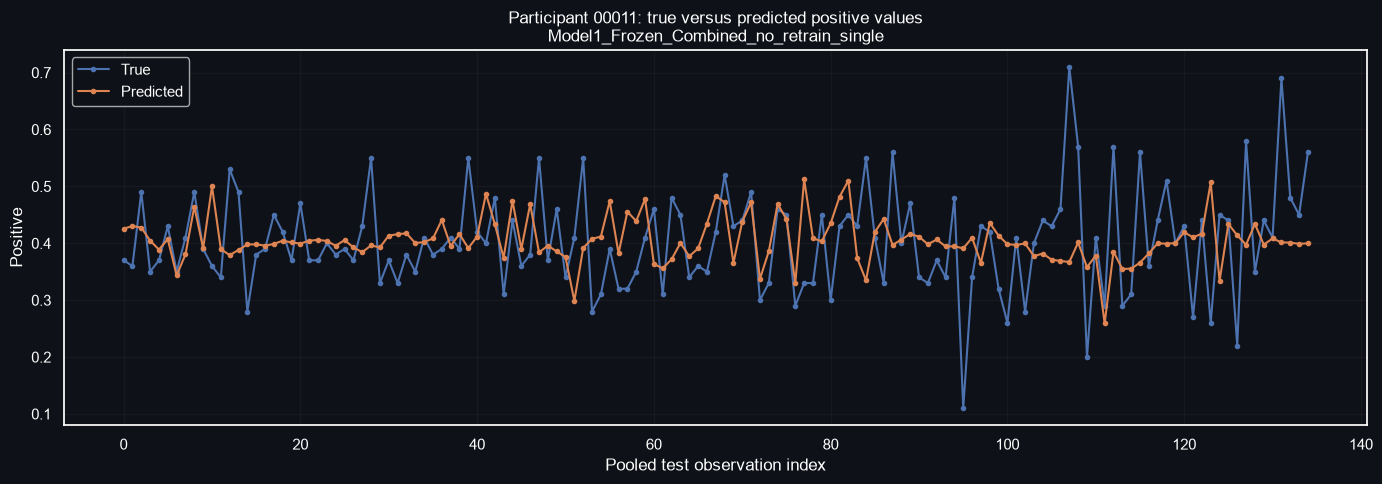

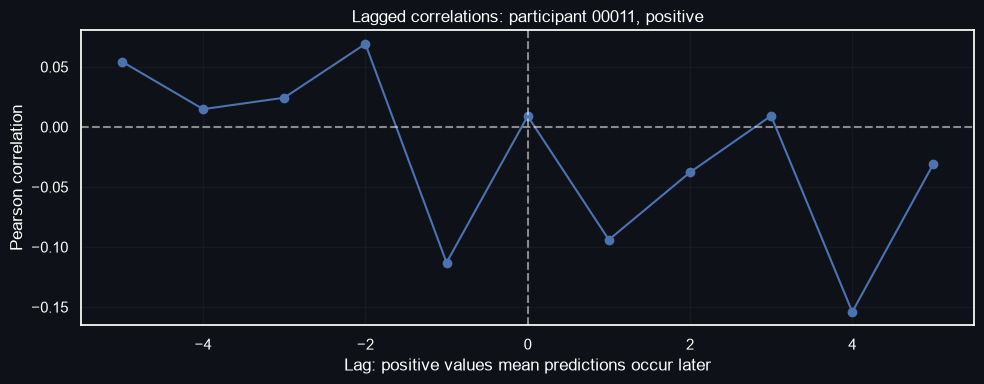

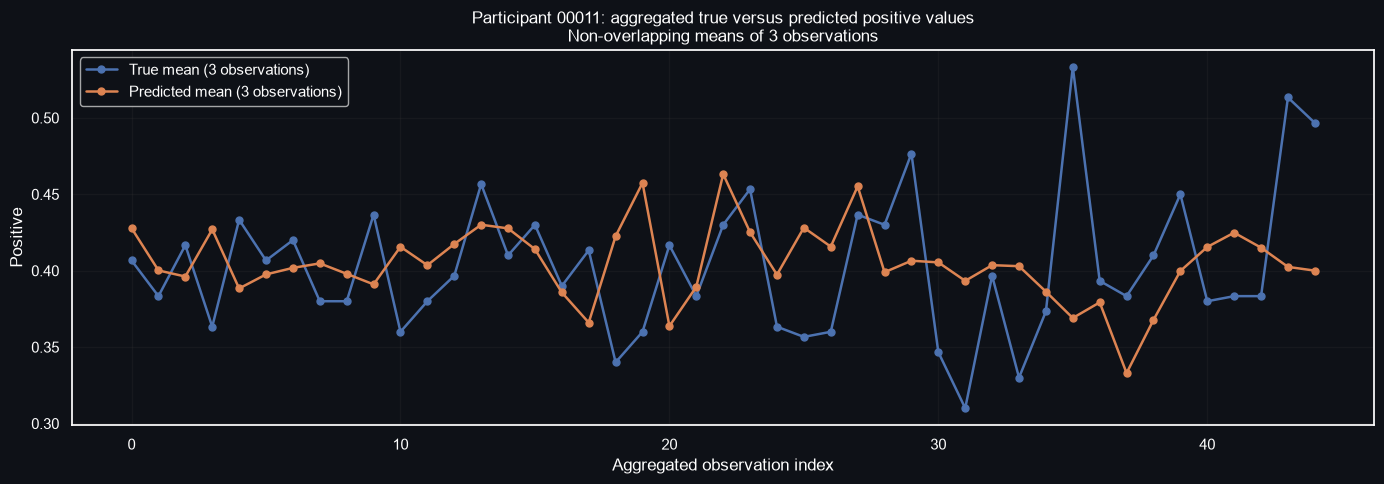

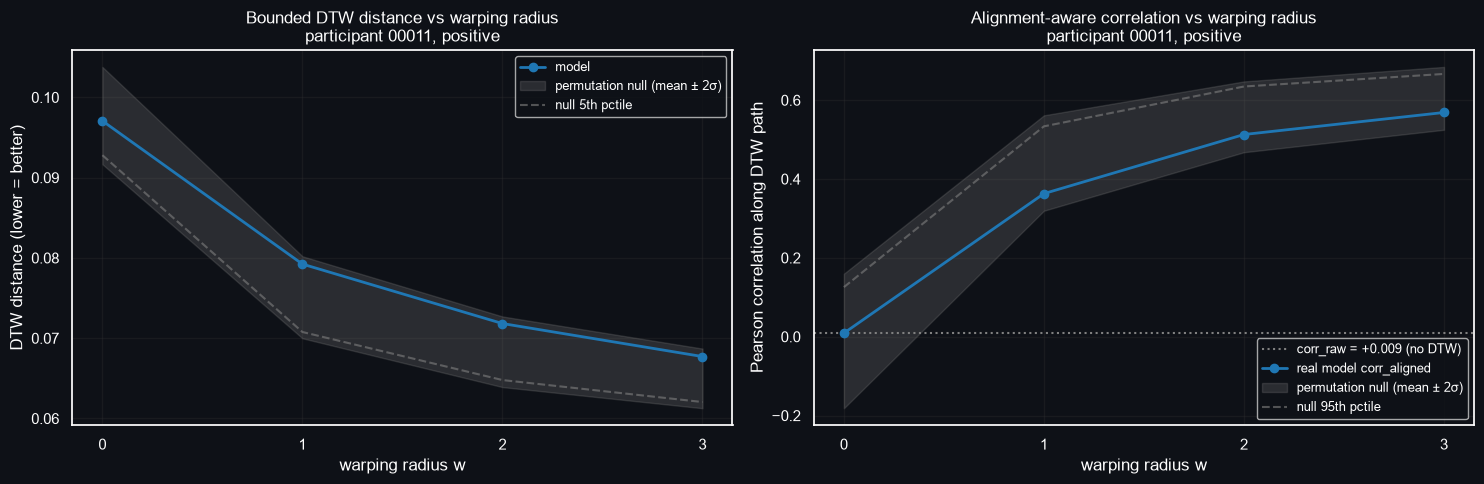


DTW summary at radius=1:
  corr_raw (independent of w)  = +0.009
  corr_aligned at w=1          = +0.363
  DTW distance at w=1          = 0.0792
  permutation p-value at w=1   = 0.955
Loaded result file:
/Users/f007qrc/Library/CloudStorage/GoogleDrive-anna.m.langener@dartmouth.edu/.shortcut-targets-by-id/1_T-CzrkNtF9QAhex6qrEOA0ZQIL7g5u5/SensingIndividualized/results_true_pred/Model1_Frozen_Combined_no_retrain_single/results_00011_positive.pth

Number of pooled observations: 135
Number of aggregated observations: 45

Performance measures:


,raw,aggregated_mean_by_3
n,135.0000,45.0000
pearson_r,0.0090,-0.0907
mse,0.0094,0.0029
rmse,0.0971,0.0539
mae,0.0735,0.0433
r2,-0.1828,-0.3815
mean_error,0.0014,0.0014



Correlation at different lags:


,lag,n_pairs,pearson_r
0,-5,130,0.0544
1,-4,131,0.0148
2,-3,132,0.0243
3,-2,133,0.0692
4,-1,134,-0.1130
5,0,135,0.0090
6,1,134,-0.0939
7,2,133,-0.0378
8,3,132,0.0093
9,4,131,-0.1540


Strongest absolute lagged correlation: lag=4, r=-0.154, n=131

Aggregated values: non-overlapping means of 3 consecutive observations


,aggregate_index,start_index,end_index,n_observations,y_true,y_pred
0,0,0,2,3,0.4067,0.4278
1,1,3,5,3,0.3833,0.4002
2,2,6,8,3,0.4167,0.3962
3,3,9,11,3,0.3633,0.4270
4,4,12,14,3,0.4333,0.3884
5,5,15,17,3,0.4067,0.3976
6,6,18,20,3,0.4200,0.4018
7,7,21,23,3,0.3800,0.4048
8,8,24,26,3,0.3800,0.3979
9,9,27,29,3,0.4367,0.3910


In [ ]:
report = participant_result_report(
    participant_id="00011",
    outcome="positive",
    variant_folder="Model1_Frozen_Combined_no_retrain_single", #Model2_LoRA_Combined_no_retrain_single Model1_Frozen_Combined_no_retrain_single
    max_lag=5,
    aggregate_by=3,
)


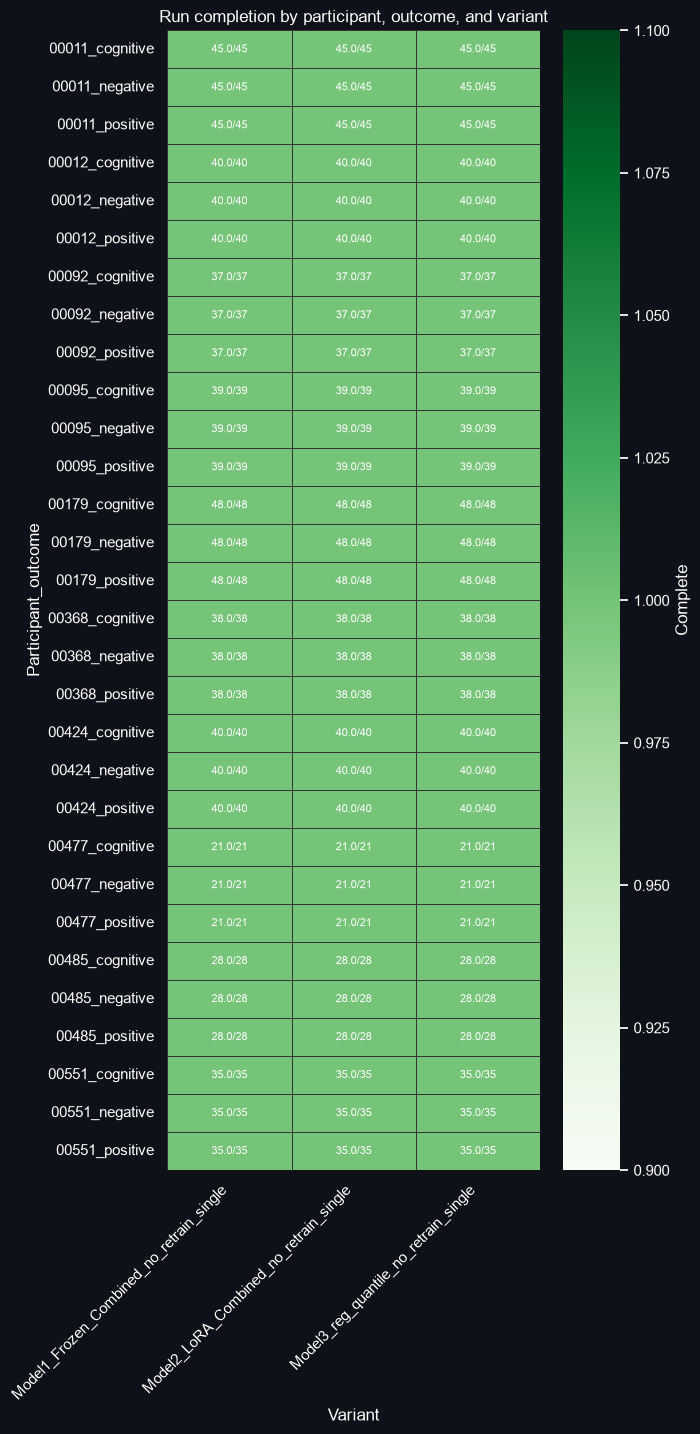

Variant summary columns: ['model_type', 'retrain_status', 'ensemble_status', 'variant_folder', 'mean_metric', 'median_metric', 'n_runs', 'mean_splits']


,model_type,retrain_status,ensemble_status,variant_folder,mean_metric,median_metric,n_runs,mean_splits
0,unknown,no_retrain,single,Model1_Frozen_Combined_no_retrain_single,0.109941,0.118528,30,37.1
1,unknown,no_retrain,single,Model2_LoRA_Combined_no_retrain_single,0.085215,0.084948,30,37.1
2,unknown,no_retrain,single,Model3_reg_quantile_no_retrain_single,0.069142,0.059735,30,37.1


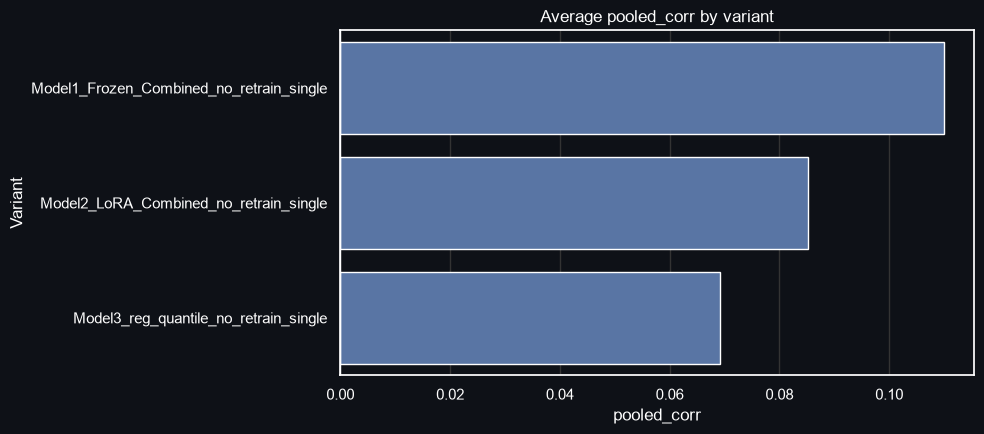

In [5]:
plot_completion_heatmap_dark(summary_df)
#plot_correlation_heatmaps_dark(summary_df, metric="pooled_corr")
variant_summary = plot_variant_comparison_dark(summary_df, metric="pooled_corr", only_complete=True)



### Helper Functions (Run First)

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

def set_dark_plot_style():
    plt.style.use("dark_background")
    sns.set_theme(
        style="darkgrid",
        rc={
            "figure.facecolor": "#0e1117",
            "axes.facecolor": "#0e1117",
            "savefig.facecolor": "#0e1117",
            "axes.edgecolor": "white",
            "axes.labelcolor": "white",
            "xtick.color": "white",
            "ytick.color": "white",
            "text.color": "white",
            "grid.color": "#333333",
        }
    )

set_dark_plot_style()

def plot_completion_heatmap_dark(summary_df):
    df = summary_df.copy()

    df["participant_outcome"] = (
        df["participant_id"].astype(str) + "_" + df["outcome"].astype(str)
    )

    df["split_label"] = (
        df["n_splits"].astype(str) + "/" + df["expected_splits"].astype(str)
    )

    pivot_complete = df.pivot_table(
        index="participant_outcome",
        columns="variant_folder",
        values="complete",
        aggfunc="first"
    )

    pivot_labels = df.pivot_table(
        index="participant_outcome",
        columns="variant_folder",
        values="split_label",
        aggfunc="first"
    )

    fig, ax = plt.subplots(
        figsize=(0.65 * len(pivot_complete.columns) + 5,
                 0.35 * len(pivot_complete.index) + 4)
    )

    fig.patch.set_facecolor("#0e1117")
    ax.set_facecolor("#0e1117")

    sns.heatmap(
        pivot_complete.astype(float),
        annot=pivot_labels,
        fmt="",
        cmap="Greens",
        linewidths=0.5,
        linecolor="#333333",
        cbar_kws={"label": "Complete"},
        annot_kws={"color": "white", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Run completion by participant, outcome, and variant", color="white", fontsize=12)
    ax.set_xlabel("Variant", color="white")
    ax.set_ylabel("Participant_outcome", color="white")
    ax.tick_params(colors="white")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

def plot_correlation_heatmaps_dark(summary_df, metric="pooled_corr"):
    df = summary_df.copy()

    outcome_order = ["negative", "cognitive", "positive"]

    for variant in sorted(df["variant_folder"].unique()):

        sub = df[df["variant_folder"] == variant].copy()

        if sub.empty:
            continue

        pivot = sub.pivot_table(
            index="participant_id",
            columns="outcome",
            values=metric,
            aggfunc="first"
        )

        pivot = pivot.reindex(columns=[x for x in outcome_order if x in pivot.columns])

        annot = pivot.copy().astype(object)

        complete_pivot = sub.pivot_table(
            index="participant_id",
            columns="outcome",
            values="complete",
            aggfunc="first"
        ).reindex(index=pivot.index, columns=pivot.columns)

        for i in pivot.index:
            for j in pivot.columns:
                value = pivot.loc[i, j]
                complete = complete_pivot.loc[i, j]

                if pd.isna(value):
                    annot.loc[i, j] = ""
                else:
                    star = "" if complete else "*"
                    annot.loc[i, j] = f"{value:.2f}{star}"

        fig, ax = plt.subplots(
            figsize=(1.3 * len(pivot.columns) + 4,
                     0.35 * len(pivot.index) + 4)
        )

        fig.patch.set_facecolor("#0e1117")
        ax.set_facecolor("#0e1117")

        sns.heatmap(
            pivot,
            annot=annot,
            fmt="",
            cmap="coolwarm",
            center=0,
            vmin=-1,
            vmax=1,
            linewidths=0.5,
            linecolor="#333333",
            cbar_kws={"label": "Pooled correlation"},
            annot_kws={"color": "white", "fontsize": 8},
            ax=ax
        )

        ax.set_title(f"Pooled correlation: {variant}\n* = incomplete run", color="white", fontsize=12)
        ax.set_xlabel("Outcome", color="white")
        ax.set_ylabel("Participant", color="white")
        ax.tick_params(colors="white")

        cbar = ax.collections[0].colorbar
        cbar.ax.yaxis.label.set_color("white")
        cbar.ax.tick_params(colors="white")

        plt.tight_layout()
        plt.show()



def plot_variant_comparison_dark(summary_df, metric="pooled_corr", only_complete=True):
    df = add_variant_columns(summary_df)

    if metric not in df.columns:
        raise ValueError(f"Metric '{metric}' not found. Available columns: {df.columns.tolist()}")

    if only_complete and "complete" in df.columns:
        df = df[df["complete"] == True].copy()

    # Remove rows without metric values
    df = df[np.isfinite(df[metric])].copy()

    if df.empty:
        print("No rows available for plotting after filtering.")
        return pd.DataFrame()

    variant_summary = (
        df.groupby(
            ["model_type", "retrain_status", "ensemble_status", "variant_folder"],
            as_index=False
        )
        .agg(
            mean_metric=(metric, "mean"),
            median_metric=(metric, "median"),
            n_runs=(metric, "count"),
            mean_splits=("n_splits", "mean")
        )
        .sort_values("mean_metric", ascending=False)
        .reset_index(drop=True)
    )

    print("Variant summary columns:", variant_summary.columns.tolist())
    display(variant_summary)

    fig, ax = plt.subplots(figsize=(10, 0.5 * len(variant_summary) + 3))

    fig.patch.set_facecolor("#0e1117")
    ax.set_facecolor("#0e1117")

    sns.barplot(
        data=variant_summary,
        y="variant_folder",
        x="mean_metric",
        ax=ax
    )

    ax.axvline(0, color="white", linewidth=1)

    ax.set_title(f"Average {metric} by variant", color="white", fontsize=12)
    ax.set_xlabel(metric, color="white")
    ax.set_ylabel("Variant", color="white")
    ax.tick_params(colors="white")

    for spine in ax.spines.values():
        spine.set_color("white")

    plt.tight_layout()
    plt.show()

    return variant_summary

In [8]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# =============================================================================
# Paths
# =============================================================================

BASE_DIR = Path(
    "/Users/f007qrc/Library/CloudStorage/GoogleDrive-anna.m.langener@dartmouth.edu/.shortcut-targets-by-id/1_T-CzrkNtF9QAhex6qrEOA0ZQIL7g5u5/SensingIndividualized"
)

RESULTS_ROOT = BASE_DIR / "results_true_pred"


# =============================================================================
# Loading helpers
# =============================================================================

def safe_torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def parse_result_file(path):
    path = Path(path)
    variant_folder = path.parent.name

    match = re.match(
        r"results_(\d+)_(negative|cognitive|positive)\.pth$",
        path.name
    )

    if match is None:
        return None

    participant_id = match.group(1)
    outcome = match.group(2)

    if variant_folder.startswith("combined_only"):
        model_type = "combined_only"
        variant = variant_folder.replace("combined_only_", "")
    elif variant_folder.startswith("main"):
        model_type = "main"
        variant = variant_folder.replace("main_", "")
    else:
        model_type = "unknown"
        variant = variant_folder

    return {
        "model_type": model_type,
        "variant": variant,
        "variant_folder": variant_folder,
        "participant_id": participant_id,
        "outcome": outcome,
        "path": path,
    }


def get_available_results(results_root=RESULTS_ROOT):
    rows = []

    for path in sorted(Path(results_root).rglob("results_*_*.pth")):
        parsed = parse_result_file(path)
        if parsed is not None:
            rows.append(parsed)

    df = pd.DataFrame(rows)

    if len(df) == 0:
        print(f"No result files found in: {results_root}")
        return df

    return df.sort_values(
        ["model_type", "variant", "participant_id", "outcome"]
    ).reset_index(drop=True)


def load_selected_results(
    model_type,
    variant,
    participant_id,
    outcome,
    results_root=RESULTS_ROOT,
    show_available=False,
):
    available_df = get_available_results(results_root)

    if show_available:
        display(available_df)

    participant_id = str(participant_id).zfill(5)

    matches = available_df[
        (available_df["model_type"] == model_type) &
        (available_df["variant"] == variant) &
        (available_df["participant_id"] == participant_id) &
        (available_df["outcome"] == outcome)
    ].copy()

    if len(matches) == 0:
        raise FileNotFoundError(
            f"No result found for model_type={model_type}, "
            f"variant={variant}, participant_id={participant_id}, outcome={outcome}."
        )

    if len(matches) > 1:
        print("Multiple matches found. Loading first match:")
        display(matches)

    result_path = matches.iloc[0]["path"]

    print(f"Loading: {result_path}")
    fold_results = safe_torch_load(result_path)
    print(f"  -> {len(fold_results)} outer folds")

    return fold_results, result_path

# =============================================================================
# One-step function: load selected result and plot
# =============================================================================

def load_and_plot_selected_results(
    model_type,
    variant,
    participant_id,
    outcome,
    results_root=RESULTS_ROOT,
    show_available=False,
    show_fold_table=True,
):
    fold_results, result_path = load_selected_results(
        model_type=model_type,
        variant=variant,
        participant_id=participant_id,
        outcome=outcome,
        results_root=results_root,
        show_available=show_available,
    )

    pred_df = collect_test_predictions(fold_results)

    if len(pred_df) == 0:
        raise ValueError("No valid y_test/y_pred pairs found in this result file.")

    metrics = compute_prediction_metrics(pred_df)

    title = (
        f"{model_type} | {variant} | "
        f"participant {str(participant_id).zfill(5)} | {outcome}"
    )

    plot_true_vs_pred_dark(
        pred_df=pred_df,
        title=title,
        show_regression_line=True,
    )

    metrics_df = pd.DataFrame([metrics])
    display(metrics_df)

    if show_fold_table:
        fold_summary = (
            pred_df.groupby("outer_i")
            .apply(
                lambda x: pd.Series(
                    {
                        "n_test_obs": len(x),
                        "fold_corr": (
                            np.corrcoef(x["y_true"], x["y_pred"])[0, 1]
                            if len(x) >= 2 and x["y_true"].std() > 0 and x["y_pred"].std() > 0
                            else np.nan
                        ),
                        "fold_mse": mean_squared_error(x["y_true"], x["y_pred"]),
                        "fold_mae": mean_absolute_error(x["y_true"], x["y_pred"]),
                    }
                )
            )
            .reset_index()
        )

        display(fold_summary)

    return {
        "fold_results": fold_results,
        "pred_df": pred_df,
        "metrics": metrics,
        "result_path": result_path,
    }


    # =============================================================================
# Metrics and plotting
# =============================================================================

def collect_test_predictions(fold_results):
    rows = []

    for fold in fold_results:
        outer_i = fold.get("outer_i", np.nan)

        y_true = np.asarray(fold.get("y_test", [])).reshape(-1)
        y_pred = np.asarray(fold.get("y_pred", [])).reshape(-1)

        if len(y_true) != len(y_pred):
            print(f"Skipping outer {outer_i}: y_test and y_pred have different lengths.")
            continue

        for point_i, (yt, yp) in enumerate(zip(y_true, y_pred)):
            rows.append(
                {
                    "outer_i": outer_i,
                    "point_i": point_i,
                    "y_true": float(yt),
                    "y_pred": float(yp),
                }
            )

    return pd.DataFrame(rows)


def compute_prediction_metrics(pred_df):
    y_true = pred_df["y_true"].to_numpy()
    y_pred = pred_df["y_pred"].to_numpy()

    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    if len(y_true) < 2:
        corr = np.nan
        r2 = np.nan
    elif np.std(y_true) == 0 or np.std(y_pred) == 0:
        corr = np.nan
        r2 = r2_score(y_true, y_pred)
    else:
        corr = np.corrcoef(y_true, y_pred)[0, 1]
        r2 = r2_score(y_true, y_pred)

    metrics = {
        "n_test_obs": len(y_true),
        "n_outer_folds": pred_df["outer_i"].nunique(),
        "correlation": corr,
        "mse": mean_squared_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2,
        "y_true_mean": np.mean(y_true),
        "y_pred_mean": np.mean(y_pred),
        "y_true_sd": np.std(y_true),
        "y_pred_sd": np.std(y_pred),
    }

    return metrics


def plot_true_vs_pred_dark(
    pred_df,
    title=None,
    show_regression_line=True,
    figsize=(7, 7),
):
    metrics = compute_prediction_metrics(pred_df)

    y_true = pred_df["y_true"].to_numpy()
    y_pred = pred_df["y_pred"].to_numpy()

    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    fig, ax = plt.subplots(figsize=figsize)

    fig.patch.set_facecolor("#0e1117")
    ax.set_facecolor("#0e1117")

    ax.scatter(
        y_true,
        y_pred,
        s=45,
        alpha=0.75,
        edgecolor="white",
        linewidth=0.5
    )

    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))

    padding = 0.05 * (max_val - min_val) if max_val > min_val else 0.05
    min_plot = min_val - padding
    max_plot = max_val + padding

    # Identity line: perfect prediction
    ax.plot(
        [min_plot, max_plot],
        [min_plot, max_plot],
        linestyle="--",
        linewidth=1.5,
        color="white",
        alpha=0.8,
        label="Perfect prediction"
    )

    # Optional regression line
    if show_regression_line and len(y_true) >= 2 and np.std(y_true) > 0:
        slope, intercept = np.polyfit(y_true, y_pred, 1)
        x_line = np.linspace(min_plot, max_plot, 100)
        y_line = slope * x_line + intercept

        ax.plot(
            x_line,
            y_line,
            linewidth=2,
            alpha=0.9,
            label="Prediction trend"
        )

    metric_text = (
        f"r = {metrics['correlation']:.3f}\n"
        f"R² = {metrics['r2']:.3f}\n"
        f"MSE = {metrics['mse']:.4f}\n"
        f"MAE = {metrics['mae']:.4f}\n"
        f"Folds = {metrics['n_outer_folds']}\n"
        f"N = {metrics['n_test_obs']}"
    )

    ax.text(
        0.05,
        0.95,
        metric_text,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=11,
        color="white",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="#1f2937",
            edgecolor="white",
            alpha=0.85
        )
    )

    ax.set_xlim(min_plot, max_plot)
    ax.set_ylim(min_plot, max_plot)

    ax.set_xlabel("True test value", color="white")
    ax.set_ylabel("Predicted test value", color="white")

    if title is not None:
        ax.set_title(title, color="white", fontsize=14)
    else:
        ax.set_title("True vs predicted test values", color="white", fontsize=14)

    ax.tick_params(colors="white")

    for spine in ax.spines.values():
        spine.set_color("white")

    ax.grid(True, color="#333333", alpha=0.8)
    ax.legend(facecolor="#0e1117", edgecolor="white", labelcolor="white")

    plt.tight_layout()
    plt.show()

    return metrics

## Specific Results

In [9]:
report = participant_result_report(
    participant_id="00092",
    outcome="negative",
    variant_folder="future_chronos2_short_no_retrain_single", #combined_only_no_retrain_ensemble, combined_only_retrain_single, combined_only_no_retrain_single
    max_lag=5,
    aggregate_by=3,
)


#new_chronos2_reg_quantile_no_retrain_single

NameError: name 'participant_result_report' is not defined

In [10]:
report = participant_result_report(
    participant_id="00092",
    outcome="positive",
    variant_folder="main_no_retrain_single", #main_no_retrain_ensemble, main_retrain_single, main_no_retrain_single, main_retrain_ensemble
    max_lag=5,
    aggregate_by=3,
)

NameError: name 'participant_result_report' is not defined

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

from IPython.display import display


# =============================================================================
# Participant-level result inspection
# =============================================================================

def _to_numpy_1d(x):
    """
    Convert tensors, lists, or arrays to a flat NumPy array.
    """
    if x is None:
        return np.array([], dtype=float)

    if torch.is_tensor(x):
        x = x.detach().cpu().numpy()

    return np.asarray(x, dtype=float).reshape(-1)


def _to_int_or_default(x, default):
    """
    Convert a scalar to int, falling back to a default value.
    """
    try:
        if torch.is_tensor(x):
            x = x.detach().cpu().item()

        return int(x)

    except (TypeError, ValueError):
        return default


def _find_participant_result_file(
    participant_id,
    outcome,
    variant_folder=None,
    results_root=RESULTS_ROOT,
):
    """
    Find the result file for one participant and outcome.

    If variant_folder is None, the complete RESULTS_ROOT is searched.
    In that case, the function raises an error if multiple variants are found.
    """
    participant_id = str(participant_id)
    outcome = str(outcome).lower()

    valid_outcomes = {"negative", "cognitive", "positive"}

    if outcome not in valid_outcomes:
        raise ValueError(
            f"outcome must be one of {sorted(valid_outcomes)}, "
            f"but received: {outcome}"
        )

    if variant_folder is None:
        search_root = Path(results_root)
    else:
        search_root = Path(results_root) / variant_folder

    if not search_root.exists():
        raise FileNotFoundError(
            f"Result folder does not exist:\n{search_root}"
        )

    matches = []

    for path in search_root.rglob(f"results_*_{outcome}.pth"):
        stored_participant_id, stored_outcome = parse_result_filename(path)

        if stored_participant_id is None:
            continue

        # Allows either "00092" or 92
        same_participant = (
            stored_participant_id == participant_id
            or (
                stored_participant_id.isdigit()
                and participant_id.isdigit()
                and int(stored_participant_id) == int(participant_id)
            )
        )

        if same_participant and stored_outcome == outcome:
            matches.append(path)

    matches = sorted(matches)

    if len(matches) == 0:
        raise FileNotFoundError(
            "No result file found for:\n"
            f"participant_id = {participant_id}\n"
            f"outcome = {outcome}\n"
            f"variant_folder = {variant_folder}"
        )

    if len(matches) > 1:
        match_text = "\n".join(str(path) for path in matches)

        raise ValueError(
            "Multiple result files were found. Please specify "
            "`variant_folder`.\n\n"
            f"Matching files:\n{match_text}"
        )

    return matches[0]


def _collect_participant_predictions(results):
    """
    Pool y_test and y_pred across outer folds.

    Results are first ordered by outer_i. Within each outer fold, the original
    order of the test observations is retained.
    """
    if not isinstance(results, list):
        raise TypeError(
            f"Expected the loaded results to be a list, got {type(results)}."
        )

    ordered_items = []

    for list_position, item in enumerate(results):
        if item is None:
            continue

        if not isinstance(item, dict):
            print(
                f"Skipping item {list_position}: "
                f"expected dict, got {type(item)}"
            )
            continue

        outer_i = _to_int_or_default(
            item.get("outer_i"),
            default=list_position,
        )

        ordered_items.append(
            (outer_i, list_position, item)
        )

    ordered_items.sort(key=lambda x: (x[0], x[1]))

    rows = []
    pooled_index = 0

    for outer_i, list_position, item in ordered_items:
        y_true = _to_numpy_1d(item.get("y_test"))
        y_pred = _to_numpy_1d(item.get("y_pred"))

        if len(y_true) == 0 and len(y_pred) == 0:
            continue

        if len(y_true) != len(y_pred):
            raise ValueError(
                f"Length mismatch for outer_i={outer_i}: "
                f"len(y_test)={len(y_true)}, "
                f"len(y_pred)={len(y_pred)}"
            )

        # Use stored test indices when available
        if "test_idx" in item:
            test_indices = _to_numpy_1d(item["test_idx"])
        else:
            test_indices = np.array([])

        if len(test_indices) != len(y_true):
            test_indices = np.full(len(y_true), np.nan)

        for within_split_i, (true_value, pred_value, test_index) in enumerate(
            zip(y_true, y_pred, test_indices)
        ):
            rows.append(
                {
                    "index": pooled_index,
                    "outer_i": outer_i,
                    "within_split_i": within_split_i,
                    "test_index": test_index,
                    "y_true": true_value,
                    "y_pred": pred_value,
                }
            )

            pooled_index += 1

    series_df = pd.DataFrame(rows)

    if series_df.empty:
        raise ValueError(
            "No valid y_test and y_pred values were found in the result file."
        )

    return series_df


def _paired_finite_values(y_true, y_pred):
    """
    Keep only observations for which true and predicted values are finite.
    """
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if len(y_true) != len(y_pred):
        raise ValueError(
            f"Length mismatch: {len(y_true)} true values and "
            f"{len(y_pred)} predicted values."
        )

    mask = np.isfinite(y_true) & np.isfinite(y_pred)

    return y_true[mask], y_pred[mask]


def _calculate_performance_metrics(y_true, y_pred):
    """
    Calculate pooled regression performance measures.
    """
    y_true, y_pred = _paired_finite_values(y_true, y_pred)

    if len(y_true) == 0:
        return {
            "n": 0,
            "pearson_r": np.nan,
            "mse": np.nan,
            "rmse": np.nan,
            "mae": np.nan,
            "r2": np.nan,
            "mean_error": np.nan,
        }

    if (
        len(y_true) >= 2
        and np.std(y_true) > 0
        and np.std(y_pred) > 0
    ):
        pearson_r = float(
            np.corrcoef(y_true, y_pred)[0, 1]
        )
    else:
        pearson_r = np.nan

    mse = float(
        mean_squared_error(y_true, y_pred)
    )

    if len(y_true) >= 2 and np.std(y_true) > 0:
        r2 = float(
            r2_score(y_true, y_pred)
        )
    else:
        r2 = np.nan

    return {
        "n": len(y_true),
        "pearson_r": pearson_r,
        "mse": mse,
        "rmse": float(np.sqrt(mse)),
        "mae": float(
            mean_absolute_error(y_true, y_pred)
        ),
        # Variance-based R², not squared Pearson correlation
        "r2": r2,
        # Positive means that predictions are too high on average
        "mean_error": float(
            np.mean(y_pred - y_true)
        ),
    }


def _calculate_lag_correlations(
    y_true,
    y_pred,
    max_lag=10,
):
    """
    Calculate Pearson correlations at different temporal lags.

    Lag convention
    --------------
    lag =  0:
        corr(y_true[t], y_pred[t])

    lag = +1:
        corr(y_true[t], y_pred[t + 1])

        A positive lag therefore means that the prediction series is shifted
        later relative to the true series.

    lag = -1:
        corr(y_true[t + 1], y_pred[t])

        A negative lag means that predictions occur earlier relative to the
        true series.
    """
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if len(y_true) != len(y_pred):
        raise ValueError(
            "y_true and y_pred need to have the same length."
        )

    max_lag = int(max_lag)

    if max_lag < 0:
        raise ValueError("max_lag must be zero or greater.")

    rows = []

    for lag in range(-max_lag, max_lag + 1):

        if lag < 0:
            # Example lag=-1:
            # true[1:] against prediction[:-1]
            lagged_true = y_true[-lag:]
            lagged_pred = y_pred[:lag]

        elif lag > 0:
            # Example lag=+1:
            # true[:-1] against prediction[1:]
            lagged_true = y_true[:-lag]
            lagged_pred = y_pred[lag:]

        else:
            lagged_true = y_true
            lagged_pred = y_pred

        lagged_true, lagged_pred = _paired_finite_values(
            lagged_true,
            lagged_pred,
        )

        if (
            len(lagged_true) >= 2
            and np.std(lagged_true) > 0
            and np.std(lagged_pred) > 0
        ):
            correlation = float(
                np.corrcoef(
                    lagged_true,
                    lagged_pred,
                )[0, 1]
            )
        else:
            correlation = np.nan

        rows.append(
            {
                "lag": lag,
                "n_pairs": len(lagged_true),
                "pearson_r": correlation,
            }
        )

    return pd.DataFrame(rows)

def _bounded_dtw_distance_and_path(y_true, y_pred, warping_radius):
    """
    Simple bounded DTW with a Sakoe-Chiba band.

    Returns
    -------
    distance : float
        Root-mean-squared alignment cost along the optimal path.
    path : list[tuple[int, int]]
        Optimal alignment path as (true_index, pred_index) pairs.
    """
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if len(y_true) == 0 or len(y_pred) == 0:
        return np.nan, []

    n_true = len(y_true)
    n_pred = len(y_pred)
    radius = int(max(0, warping_radius))

    costs = np.full((n_true + 1, n_pred + 1), np.inf, dtype=float)
    back = np.full((n_true + 1, n_pred + 1), -1, dtype=np.int8)
    costs[0, 0] = 0.0

    for i in range(1, n_true + 1):
        j_start = max(1, i - radius)
        j_end = min(n_pred, i + radius)

        for j in range(j_start, j_end + 1):
            local_cost = float((y_true[i - 1] - y_pred[j - 1]) ** 2)
            candidates = (
                costs[i - 1, j - 1],  # diagonal
                costs[i - 1, j],      # up
                costs[i, j - 1],      # left
            )
            move = int(np.argmin(candidates))
            best_prev = candidates[move]

            if np.isfinite(best_prev):
                costs[i, j] = local_cost + best_prev
                back[i, j] = move

    if not np.isfinite(costs[n_true, n_pred]):
        return np.nan, []

    path = []
    i, j = n_true, n_pred

    while i > 0 and j > 0:
        path.append((i - 1, j - 1))
        move = back[i, j]

        if move == 0:
            i -= 1
            j -= 1
        elif move == 1:
            i -= 1
        elif move == 2:
            j -= 1
        else:
            break

    path.reverse()

    path_length = max(len(path), 1)
    distance = float(np.sqrt(costs[n_true, n_pred] / path_length))

    return distance, path


def _corr_along_dtw_path(y_true, y_pred, path):
    """
    Pearson correlation after aligning true and predicted values along a DTW path.
    """
    if not path:
        return np.nan

    aligned_true = np.asarray([y_true[i] for i, _ in path], dtype=float)
    aligned_pred = np.asarray([y_pred[j] for _, j in path], dtype=float)

    return _calculate_performance_metrics(aligned_true, aligned_pred)["pearson_r"]


def _compute_dtw_sweep_df(
    y_true,
    y_pred,
    warping_radii,
    n_perm=200,
    seed=0,
):
    """
    Compute DTW distance and alignment-aware correlation across warping radii.

    The permutation null shuffles predictions to destroy temporal order while
    preserving their marginal distribution.
    """
    y_true, y_pred = _paired_finite_values(y_true, y_pred)
    corr_raw = _calculate_performance_metrics(y_true, y_pred)["pearson_r"]
    rng = np.random.default_rng(seed)

    rows = []

    for warping_radius in warping_radii:
        d_real, path = _bounded_dtw_distance_and_path(
            y_true=y_true,
            y_pred=y_pred,
            warping_radius=warping_radius,
        )

        corr_aligned = _corr_along_dtw_path(
            y_true=y_true,
            y_pred=y_pred,
            path=path,
        )

        null_distances = []
        null_corrs = []

        for _ in range(int(n_perm)):
            permuted_pred = rng.permutation(y_pred)

            d_null, path_null = _bounded_dtw_distance_and_path(
                y_true=y_true,
                y_pred=permuted_pred,
                warping_radius=warping_radius,
            )

            if np.isfinite(d_null):
                null_distances.append(d_null)

            corr_null = _corr_along_dtw_path(
                y_true=y_true,
                y_pred=permuted_pred,
                path=path_null,
            )

            if np.isfinite(corr_null):
                null_corrs.append(corr_null)

        null_distances = np.asarray(null_distances, dtype=float)
        null_corrs = np.asarray(null_corrs, dtype=float)

        if len(null_distances) > 0:
            null_mean = float(np.mean(null_distances))
            null_std = float(np.std(null_distances))
            null_p05 = float(np.percentile(null_distances, 5))
            null_p_value = (
                float(np.mean(null_distances <= d_real))
                if np.isfinite(d_real)
                else np.nan
            )
        else:
            null_mean = np.nan
            null_std = np.nan
            null_p05 = np.nan
            null_p_value = np.nan

        if len(null_corrs) > 0:
            corr_null_mean = float(np.mean(null_corrs))
            corr_null_std = float(np.std(null_corrs))
            corr_null_p95 = float(np.percentile(null_corrs, 95))
            corr_null_p_value = (
                float(np.mean(null_corrs >= corr_aligned))
                if np.isfinite(corr_aligned)
                else np.nan
            )
        else:
            corr_null_mean = np.nan
            corr_null_std = np.nan
            corr_null_p95 = np.nan
            corr_null_p_value = np.nan

        rows.append(
            {
                "warping_radius": int(warping_radius),
                "d_real": d_real,
                "corr_raw": corr_raw,
                "corr_aligned": corr_aligned,
                "null_mean": null_mean,
                "null_std": null_std,
                "null_p05": null_p05,
                "null_p_value": null_p_value,
                "corr_null_mean": corr_null_mean,
                "corr_null_std": corr_null_std,
                "corr_null_p95": corr_null_p95,
                "corr_null_p_value": corr_null_p_value,
            }
        )

    return pd.DataFrame(rows)

def _aggregate_non_overlapping(
    series_df,
    aggregate_by=3,
):
    """
    Average true and predicted values within consecutive,
    non-overlapping groups.

    Example for aggregate_by=3:
        observations 0, 1, 2 -> aggregate 0
        observations 3, 4, 5 -> aggregate 1
        observations 6, 7, 8 -> aggregate 2

    A final incomplete group is dropped.
    """
    aggregate_by = int(aggregate_by)

    if aggregate_by < 1:
        raise ValueError("aggregate_by must be at least 1.")

    n_complete_groups = len(series_df) // aggregate_by
    n_used = n_complete_groups * aggregate_by
    n_dropped = len(series_df) - n_used

    trimmed_df = series_df.iloc[:n_used].copy()

    if trimmed_df.empty:
        columns = [
            "aggregate_index",
            "start_index",
            "end_index",
            "n_observations",
            "y_true",
            "y_pred",
        ]

        return pd.DataFrame(columns=columns), n_dropped

    trimmed_df["aggregate_index"] = (
        np.arange(len(trimmed_df)) // aggregate_by
    )

    aggregated_df = (
        trimmed_df
        .groupby("aggregate_index", as_index=False)
        .agg(
            start_index=("index", "first"),
            end_index=("index", "last"),
            n_observations=("index", "size"),
            y_true=("y_true", "mean"),
            y_pred=("y_pred", "mean"),
        )
    )

    return aggregated_df, n_dropped

def participant_result_report(
    participant_id,
    outcome,
    variant_folder=None,
    results_root=RESULTS_ROOT,
    max_lag=10,
    aggregate_by=3,
    show_plots=True,
    show_tables=True,
):
    """
    Create a detailed report for one participant result file.

    Provides
    --------
    1. Line plot of predicted versus true values.
    2. Performance metrics for unaggregated observations.
    3. Pearson correlations at different lags.
    4. Performance metrics after non-overlapping mean aggregation.

    Returns
    -------
    report : dict
        Contains:
        - result_path
        - series
        - performance
        - lag_correlations
        - best_lag
        - aggregated_series
        - raw_metrics
        - aggregated_metrics
        - n_dropped_from_aggregation
        - prediction_figure
        - lag_figure
    """
    result_path = _find_participant_result_file(
        participant_id=participant_id,
        outcome=outcome,
        variant_folder=variant_folder,
        results_root=results_root,
    )

    results = safe_torch_load(result_path)

    series_df = _collect_participant_predictions(
        results
    )

    # -------------------------------------------------------------------------
    # 1. Raw performance
    # -------------------------------------------------------------------------

    raw_metrics = _calculate_performance_metrics(
        series_df["y_true"],
        series_df["y_pred"],
    )

    # -------------------------------------------------------------------------
    # 2. Lagged correlations
    # -------------------------------------------------------------------------

    lag_df = _calculate_lag_correlations(
        y_true=series_df["y_true"],
        y_pred=series_df["y_pred"],
        max_lag=max_lag,
    )

    valid_lags = lag_df.dropna(
        subset=["pearson_r"]
    )

    if valid_lags.empty:
        best_lag = None
    else:
        best_lag_index = (
            valid_lags["pearson_r"]
            .abs()
            .idxmax()
        )

        best_lag = valid_lags.loc[
            best_lag_index
        ].to_dict()

    # -------------------------------------------------------------------------
    # 3. Non-overlapping aggregation
    # -------------------------------------------------------------------------

    aggregated_df, n_dropped = _aggregate_non_overlapping(
        series_df=series_df,
        aggregate_by=aggregate_by,
    )

    aggregated_metrics = _calculate_performance_metrics(
        aggregated_df["y_true"],
        aggregated_df["y_pred"],
    )

    metric_order = [
        "n",
        "pearson_r",
        "mse",
        "rmse",
        "mae",
        "r2",
        "mean_error",
    ]

    performance_df = pd.DataFrame(
        {
            "raw": pd.Series(raw_metrics),
            f"aggregated_mean_by_{aggregate_by}": pd.Series(
                aggregated_metrics
            ),
        }
    ).loc[metric_order]

    # -------------------------------------------------------------------------
    # 4. Predicted-versus-true plot
    # -------------------------------------------------------------------------

    prediction_figure = None
    aggregated_figure = None
    lag_figure = None
    dtw_figure = None
    dtw_sweep_df = None

    if show_plots:
        prediction_figure, ax = plt.subplots(
            figsize=(14, 5)
        )

        ax.plot(
            series_df["index"],
            series_df["y_true"],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label="True",
        )

        ax.plot(
            series_df["index"],
            series_df["y_pred"],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label="Predicted",
        )

        ax.set_title(
            f"Participant {participant_id}: "
            f"true versus predicted {outcome} values\n"
            f"{result_path.parent.name}"
        )

        ax.set_xlabel("Pooled test observation index")
        ax.set_ylabel(outcome.capitalize())
        ax.legend()
        ax.grid(alpha=0.25)

        prediction_figure.tight_layout()
        plt.show()

        # Lag-correlation plot
        lag_figure, ax = plt.subplots(
            figsize=(10, 4)
        )

        ax.plot(
            lag_df["lag"],
            lag_df["pearson_r"],
            marker="o",
            linewidth=1.5,
        )

        ax.axvline(
            0,
            linestyle="--",
            alpha=0.5,
        )

        ax.axhline(
            0,
            linestyle="--",
            alpha=0.5,
        )

        ax.set_title(
            f"Lagged correlations: participant {participant_id}, "
            f"{outcome}"
        )

        ax.set_xlabel(
            "Lag: positive values mean predictions occur later"
        )

        ax.set_ylabel("Pearson correlation")
        ax.grid(alpha=0.25)

        lag_figure.tight_layout()
        plt.show()
        

        # Aggregated predicted-versus-true plot
        aggregated_figure, ax = plt.subplots(
            figsize=(14, 5)
        )

        ax.plot(
            aggregated_df["aggregate_index"],
            aggregated_df["y_true"],
            marker="o",
            markersize=5,
            linewidth=1.8,
            label=f"True mean ({aggregate_by} observations)",
        )

        ax.plot(
            aggregated_df["aggregate_index"],
            aggregated_df["y_pred"],
            marker="o",
            markersize=5,
            linewidth=1.8,
            label=f"Predicted mean ({aggregate_by} observations)",
        )

        ax.set_title(
            f"Participant {participant_id}: aggregated true versus predicted "
            f"{outcome} values\n"
            f"Non-overlapping means of {aggregate_by} observations"
        )

        ax.set_xlabel("Aggregated observation index")
        ax.set_ylabel(outcome.capitalize())
        ax.legend()
        ax.grid(alpha=0.25)

        aggregated_figure.tight_layout()
        plt.show()


            # DTW sweep plot
        fold_sizes = (
            series_df
            .groupby("outer_i")
            .size()
            .to_numpy()
        )

        max_radius = int(fold_sizes.max()) if len(fold_sizes) > 0 else 0
        warping_radii = list(range(max_radius + 1))

        dtw_sweep_df = _compute_dtw_sweep_df(
            y_true=series_df["y_true"],
            y_pred=series_df["y_pred"],
            warping_radii=warping_radii,
            n_perm=200,
            seed=0,
        )

        dtw_figure, axes = plt.subplots(
            1,
            2,
            figsize=(15, 5),
        )

        x_labels = dtw_sweep_df["warping_radius"].astype(str).tolist()
        x = np.arange(len(x_labels))

        # LEFT: DTW distance + permutation null band
        ax = axes[0]
        ax.plot(
            x,
            dtw_sweep_df["d_real"],
            marker="o",
            linewidth=2,
            label="model",
            color="tab:blue",
        )

        null_mean = dtw_sweep_df["null_mean"].values
        null_std = dtw_sweep_df["null_std"].values

        ax.fill_between(
            x,
            null_mean - 2 * null_std,
            null_mean + 2 * null_std,
            alpha=0.25,
            color="grey",
            label="permutation null (mean ± 2σ)",
        )

        ax.plot(
            x,
            dtw_sweep_df["null_p05"],
            linestyle="--",
            color="grey",
            alpha=0.6,
            label="null 5th pctile",
        )

        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_xlabel("warping radius w")
        ax.set_ylabel("DTW distance (lower = better)")
        ax.set_title(
            f"Bounded DTW distance vs warping radius\n"
            f"participant {participant_id}, {outcome}"
        )
        ax.legend(fontsize=9)
        ax.grid(alpha=0.3)
        
        # RIGHT: alignment-aware correlation + permutation null
        ax = axes[1]

        if len(dtw_sweep_df) > 0:
            ax.axhline(
                dtw_sweep_df["corr_raw"].iloc[0],
                color="grey",
                linestyle=":",
                label=(
                    f"corr_raw = "
                    f"{dtw_sweep_df['corr_raw'].iloc[0]:+.3f} "
                    f"(no DTW)"
                ),
            )

        ax.plot(
            x,
            dtw_sweep_df["corr_aligned"],
            marker="o",
            linewidth=2,
            label="real model corr_aligned",
            color="tab:blue",
        )

        corr_null_mean = dtw_sweep_df["corr_null_mean"].values
        corr_null_std = dtw_sweep_df["corr_null_std"].values

        ax.fill_between(
            x,
            corr_null_mean - 2 * corr_null_std,
            corr_null_mean + 2 * corr_null_std,
            alpha=0.25,
            color="grey",
            label="permutation null (mean ± 2σ)",
        )

        ax.plot(
            x,
            dtw_sweep_df["corr_null_p95"],
            linestyle="--",
            color="grey",
            alpha=0.6,
            label="null 95th pctile",
        )

        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_xlabel("warping radius w")
        ax.set_ylabel("Pearson correlation along DTW path")
        ax.set_title(
            f"Alignment-aware correlation vs warping radius\n"
            f"participant {participant_id}, {outcome}"
        )
        ax.legend(fontsize=9)
        ax.grid(alpha=0.3)

        dtw_figure.tight_layout()
        plt.show()

        if 1 in dtw_sweep_df["warping_radius"].values:
            w1_row = dtw_sweep_df[
                dtw_sweep_df["warping_radius"] == 1
            ].iloc[0]

            print("\nDTW summary at radius=1:")
            print(
                f"  corr_raw (independent of w)  = "
                f"{w1_row['corr_raw']:+.3f}"
            )
            print(
                f"  corr_aligned at w=1          = "
                f"{w1_row['corr_aligned']:+.3f}"
            )
            print(
                f"  DTW distance at w=1          = "
                f"{w1_row['d_real']:.4f}"
            )
            print(
                f"  permutation p-value at w=1   = "
                f"{w1_row['null_p_value']:.3f}"
            )

    # -------------------------------------------------------------------------
    # 5. Display results
    # -------------------------------------------------------------------------

    if show_tables:
        print(f"Loaded result file:\n{result_path}")
        print(f"\nNumber of pooled observations: {len(series_df)}")
        print(
            f"Number of aggregated observations: "
            f"{len(aggregated_df)}"
        )

        if n_dropped > 0:
            print(
                f"Observations dropped from the final incomplete "
                f"aggregation group: {n_dropped}"
            )

        print("\nPerformance measures:")
        display(
            performance_df.round(4)
        )

        print("\nCorrelation at different lags:")
        display(
            lag_df.round(4)
        )

        if best_lag is not None:
            print(
                "Strongest absolute lagged correlation: "
                f"lag={int(best_lag['lag'])}, "
                f"r={best_lag['pearson_r']:.3f}, "
                f"n={int(best_lag['n_pairs'])}"
            )

        print(
            f"\nAggregated values: non-overlapping means of "
            f"{aggregate_by} consecutive observations"
        )

        display(
            aggregated_df.round(4)
        )

    return {
        "result_path": result_path,
        "series": series_df,
        "performance": performance_df,
        "raw_metrics": raw_metrics,
        "lag_correlations": lag_df,
        "best_lag": best_lag,
        "aggregated_figure": aggregated_figure,
        "aggregated_series": aggregated_df,
        "aggregated_metrics": aggregated_metrics,
        "n_dropped_from_aggregation": n_dropped,
        "prediction_figure": prediction_figure,
        "lag_figure": lag_figure,
        "dtw_figure": dtw_figure,
        "dtw_sweep": dtw_sweep_df,
    }

In [ ]:
hparams_df = extract_best_hyperparameters()

#show(hparams_df)

# Hyperparameter columns
hparam_cols = [
    col for col in hparams_df.columns
    if col.startswith("hparam.")
]

# Count how often each value was selected
selection_counts = []

for col in hparam_cols:
    counts = (
        hparams_df
        .groupby(
            ["variant_folder", "outcome", col],
            dropna=False
        )
        .size()
        .reset_index(name="n_selected")
        .rename(columns={col: "value"})
    )

    counts["hyperparameter"] = col.replace("hparam.", "")

    selection_counts.append(counts)

selection_counts_df = pd.concat(
    selection_counts,
    ignore_index=True
)

selection_counts_df = (
    selection_counts_df[
        [
            "variant_folder",
            "outcome",
            "hyperparameter",
            "value",
            "n_selected",
        ]
    ]
    .sort_values(
        [
            "variant_folder",
            "outcome",
            "hyperparameter",
            "n_selected",
        ],
        ascending=[True, True, True, False]
    )
    .reset_index(drop=True)
)

#show(selection_counts_df)


overall_selection_counts = []

for col in hparam_cols:
    counts = (
        hparams_df[col]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="n_selected")
    )

    counts["hyperparameter"] = col.replace("hparam.", "")
    overall_selection_counts.append(counts)

overall_selection_counts_df = pd.concat(
    overall_selection_counts,
    ignore_index=True
)[
    ["hyperparameter", "value", "n_selected"]
].sort_values(
    ["hyperparameter", "n_selected"],
    ascending=[True, False]
)

#show(overall_selection_counts_df)

NameError: name 'extract_best_hyperparameters' is not defined

In [12]:
import json
from pathlib import Path

import numpy as np
import pandas as pd


def extract_best_hyperparameters(results_root=RESULTS_ROOT):
    """
    Extract the selected hyperparameters from every outer fold in every
    saved result file.

    Returns
    -------
    hparams_df : pd.DataFrame
        One row per participant, outcome, variant, and outer fold.
    """
    rows = []

    result_files = sorted(
        Path(results_root).rglob("results_*_*.pth")
    )

    for result_path in result_files:
        participant_id, outcome = parse_result_filename(
            result_path
        )

        if participant_id is None:
            continue

        variant_folder = result_path.parent.name

        try:
            results = safe_torch_load(result_path)
        except Exception as error:
            print(
                f"Could not load {result_path}: {error}"
            )
            continue

        if not isinstance(results, list):
            print(
                f"Skipping {result_path}: expected list, "
                f"got {type(results).__name__}"
            )
            continue

        for list_position, item in enumerate(results):
            if item is None:
                continue

            best_hparams = item.get(
                "best_hparams",
                {}
            )

            if best_hparams is None:
                best_hparams = {}

            base_row = {
                "variant_folder": variant_folder,
                "participant_id": participant_id,
                "outcome": outcome,
                "outer_i": item.get(
                    "outer_i",
                    list_position,
                ),
                "best_inner_i": item.get(
                    "best_inner_i",
                    np.nan,
                ),
                "best_inner_val_loss": item.get(
                    "best_inner_val_loss",
                    np.nan,
                ),
                "selected_seeds": item.get(
                    "selected_seeds",
                    [],
                ),
                "retrain_final": item.get(
                    "retrain_final",
                    np.nan,
                ),
                "effective_top_k": item.get(
                    "effective_top_k",
                    np.nan,
                ),
            }

            # Flatten nested hyperparameter dictionaries
            flattened_hparams = pd.json_normalize(
                best_hparams,
                sep=".",
            ).to_dict(
                orient="records"
            )

            if flattened_hparams:
                flattened_hparams = flattened_hparams[0]
            else:
                flattened_hparams = {}

            # Prefix hyperparameter columns
            flattened_hparams = {
                f"hparam.{key}": value
                for key, value in flattened_hparams.items()
            }

            base_row.update(flattened_hparams)
            rows.append(base_row)

    hparams_df = pd.DataFrame(rows)

    if not hparams_df.empty:
        hparams_df = hparams_df.sort_values(
            [
                "variant_folder",
                "participant_id",
                "outcome",
                "outer_i",
            ]
        ).reset_index(drop=True)

    return hparams_df

In [13]:
# =============================================================================
# Combine Model result files with baseline results
# =============================================================================

BASELINE_RESULTS_PATH = Path.cwd() / "baseline_outputs" / "baseline_results.csv"

COMBINED_RESULTS_SAVE_PATH = (
    RESULTS_ROOT / "model_and_baseline_results.csv"
)


# -----------------------------------------------------------------------------
# 1. Read neural-model result files from folders beginning with "Model"
# -----------------------------------------------------------------------------

model_result_files = sorted(
    path
    for path in RESULTS_ROOT.rglob("results_*_*.pth")
    if path.parent.name.startswith("Model")
)

model_rows = []

for path in model_result_files:
    row = summarize_result_file(path)

    if row is not None:
        model_rows.append(row)

model_results_df = pd.DataFrame(model_rows)

if model_results_df.empty:
    print(
        "No result files were found inside folders "
        f"starting with 'Model' under:\n{RESULTS_ROOT}"
    )
else:
    model_results_df = add_variant_columns(
        model_results_df
    )

    # Give the columns the same names used in the baseline table.
    model_results_df = model_results_df.rename(
        columns={
            "outcome": "target",
            "variant_folder": "model",
            "n_test_obs": "n",
            "pooled_corr": "corr",
            "pooled_corr_p": "corr_p",
            "pooled_mse": "mse",
            "pooled_mae": "mae",
        }
    )

    model_results_df["target"] = (
        model_results_df["target"]
        .str.capitalize()
    )

    model_results_df["result_source"] = (
        "Neural model"
    )


# -----------------------------------------------------------------------------
# 2. Read baseline results
# -----------------------------------------------------------------------------

if not BASELINE_RESULTS_PATH.exists():
    raise FileNotFoundError(
        "Baseline results file not found:\n"
        f"{BASELINE_RESULTS_PATH}"
    )

baseline_results_df = pd.read_csv(
    BASELINE_RESULTS_PATH,
    dtype={
        "participant_id": str,
    },
)

baseline_results_df["participant_id"] = (
    baseline_results_df["participant_id"]
    .astype(str)
    .str.zfill(5)
)

baseline_results_df["result_source"] = "Baseline"

# Baseline correlations currently have no p-values.
if "corr_p" not in baseline_results_df.columns:
    baseline_results_df["corr_p"] = np.nan

if "complete" not in baseline_results_df.columns:
    baseline_results_df["complete"] = True

if "file_path" not in baseline_results_df.columns:
    baseline_results_df["file_path"] = str(
        BASELINE_RESULTS_PATH
    )


# -----------------------------------------------------------------------------
# 3. Retain common comparison columns
# -----------------------------------------------------------------------------

comparison_columns = [
    "participant_id",
    "target",
    "model",
    "result_source",
    "n",
    "corr",
    "corr_p",
    "mse",
    "mae",
    "r2",
    "complete",
    "file_path",
]


def add_missing_columns(df, columns):
    df = df.copy()

    for column in columns:
        if column not in df.columns:
            df[column] = np.nan

    return df[columns]


baseline_comparison_df = add_missing_columns(
    baseline_results_df,
    comparison_columns,
)

model_comparison_df = add_missing_columns(
    model_results_df,
    comparison_columns,
)


# -----------------------------------------------------------------------------
# 4. Combine and save
# -----------------------------------------------------------------------------

combined_results_df = pd.concat(
    [
        baseline_comparison_df,
        model_comparison_df,
    ],
    ignore_index=True,
)

combined_results_df["participant_id"] = (
    combined_results_df["participant_id"]
    .astype(str)
    .str.zfill(5)
)

combined_results_df["target"] = pd.Categorical(
    combined_results_df["target"],
    categories=[
        "Negative",
        "Cognitive",
        "Positive",
    ],
    ordered=True,
)

combined_results_df = (
    combined_results_df
    .sort_values(
        [
            "participant_id",
            "target",
            "result_source",
            "model",
        ]
    )
    .reset_index(drop=True)
)

combined_results_df.to_csv(
    COMBINED_RESULTS_SAVE_PATH,
    index=False,
)

print(
    f"Found {len(model_result_files)} "
    "neural-model result files."
)
print(
    f"Loaded {len(baseline_results_df)} "
    "baseline rows."
)
print(
    f"Saved combined results to:\n"
    f"{COMBINED_RESULTS_SAVE_PATH}"
)

display(combined_results_df)

FileNotFoundError: Baseline results file not found:
/Users/f007qrc/Library/CloudStorage/GoogleDrive-anna.m.langener@dartmouth.edu/.shortcut-targets-by-id/1_T-CzrkNtF9QAhex6qrEOA0ZQIL7g5u5/SensingIndividualized/Code/baseline_outputs/baseline_results.csv

In [ ]:
mean_corr_table = (
    combined_results_df
    .groupby(
        ["target", "model"],
        observed=False,
    )["corr"]
    .mean()
    .unstack("model")
)

display(
    mean_corr_table.style.format("{:.3f}")
)

In [14]:
plot_df = (
    combined_results_df
    .groupby(
        ["target", "model"],
        observed=False,
    )["corr"]
    .mean()
    .reset_index()
)

for target_name in [
    "Negative",
    "Cognitive",
    "Positive",
]:
    current = plot_df[
        plot_df["target"] == target_name
    ].dropna(subset=["corr"])

    plt.figure(figsize=(10, 5))

    plt.bar(
        current["model"],
        current["corr"],
    )

    plt.axhline(
        0,
        linewidth=1,
    )

    plt.title(
        f"Mean correlation: {target_name}"
    )
    plt.ylabel("Pearson correlation")
    plt.xticks(
        rotation=45,
        ha="right",
    )
    plt.tight_layout()
    plt.show()

NameError: name 'combined_results_df' is not defined